# Q1 Part 3 — Regional Performance Insights

## Objective

Identify the top 5 states with the highest order count, calculate total sales and average profit for each state, identify regional disparities, and recommend regions or cities that should be prioritized for improvement.

### Methodology

The analysis uses the **List of Orders** dataset for order-level regional information and the **Order Details** data reused from Q1 Part 1 to calculate sales and profit at the Order ID level.

Average profit is calculated at the **order level first** and then averaged by state/city. This prevents orders containing multiple product line items from receiving disproportionate weight.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = Path.cwd().resolve().parents[0]

LIST_ORDERS_PATH = BASE_DIR / "data" / "processed" / "list_of_orders.csv"
MERGED_DATA_PATH = (
    BASE_DIR.parent
    / "Part_1_Sales_Profitability"
    / "data"
    / "processed"
    / "merged_order_data.csv"
)

list_orders = pd.read_csv(LIST_ORDERS_PATH)
merged_data = pd.read_csv(MERGED_DATA_PATH)

print("List of Orders shape:", list_orders.shape)
print("Order Details / merged data shape:", merged_data.shape)


List of Orders shape: (500, 5)
Order Details / merged data shape: (1500, 10)


## 1. Data Validation

The List of Orders dataset should contain one row per order. The merged order-detail dataset contains multiple line items per order, so it is aggregated to one record per Order ID before regional calculations.


In [2]:
assert list_orders["Order ID"].nunique() == len(list_orders), (
    "List of Orders should contain one unique row per Order ID."
)

assert merged_data["Order ID"].nunique() == 500, (
    "Expected 500 unique orders in the merged dataset."
)

print("List of Orders unique orders:", list_orders["Order ID"].nunique())
print("Merged data unique orders:", merged_data["Order ID"].nunique())
print("Data validation passed.")


List of Orders unique orders: 500
Merged data unique orders: 500
Data validation passed.


## 2. Aggregate Sales and Profit at Order Level

Each order can contain multiple product line items. Therefore, sales and profit are summed by Order ID before being joined to the List of Orders dataset.


In [3]:
order_metrics = (
    merged_data
    .groupby("Order ID", as_index=False)
    .agg(
        Total_Sales=("Amount", "sum"),
        Total_Profit=("Profit", "sum")
    )
)

orders = list_orders.merge(
    order_metrics,
    on="Order ID",
    how="left",
    validate="one_to_one"
)

assert len(orders) == 500
assert orders["Total_Sales"].notna().all()
assert orders["Total_Profit"].notna().all()

orders.head()


,Order ID,Order Date,CustomerName,State,City,Total_Sales,Total_Profit
0,B-25601,2018-04-01,Bharat,Gujarat,Ahmedabad,1429,-1218
1,B-25602,2018-04-01,Pearl,Maharashtra,Pune,3889,975
2,B-25603,2018-04-03,Jahan,Madhya Pradesh,Bhopal,2025,-180
3,B-25604,2018-04-03,Divsha,Rajasthan,Jaipur,222,22
4,B-25605,2018-04-05,Kasheen,West Bengal,Kolkata,75,0


## 3. Top 5 States by Order Count


In [4]:
state_analysis = (
    orders
    .groupby("State")
    .agg(
        Order_Count=("Order ID", "nunique"),
        Total_Sales=("Total_Sales", "sum"),
        Average_Profit=("Total_Profit", "mean")
    )
    .reset_index()
    .sort_values(
        ["Order_Count", "Total_Sales"],
        ascending=[False, False]
    )
)

top_5_states = state_analysis.head(5).copy()

top_5_states["Total_Sales"] = top_5_states["Total_Sales"].round(2)
top_5_states["Average_Profit"] = top_5_states["Average_Profit"].round(2)

top_5_states


,State,Order_Count,Total_Sales,Average_Profit
10,Madhya Pradesh,101,105140,54.96
11,Maharashtra,90,95348,68.62
14,Rajasthan,32,21149,39.28
4,Gujarat,27,21058,17.22
13,Punjab,25,16786,-24.36


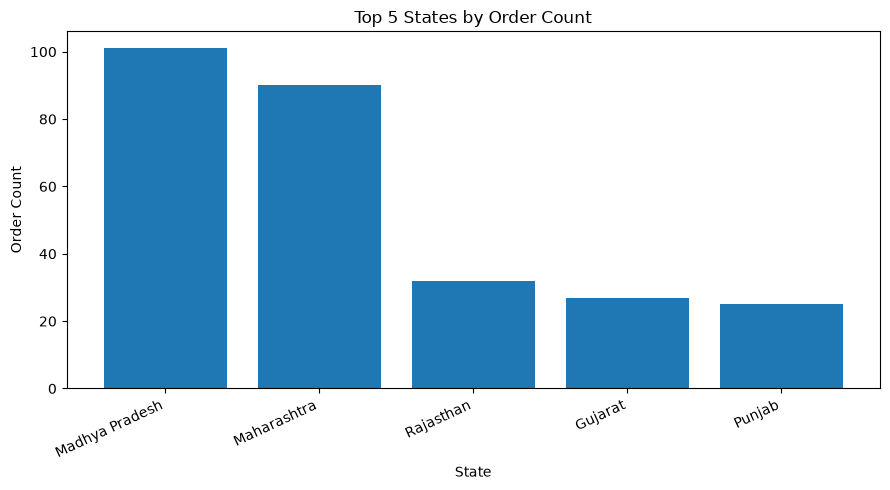

In [5]:
# Visualize order count across the top 5 states

plt.figure(figsize=(9, 5))
plt.bar(top_5_states["State"], top_5_states["Order_Count"])
plt.title("Top 5 States by Order Count")
plt.xlabel("State")
plt.ylabel("Order Count")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


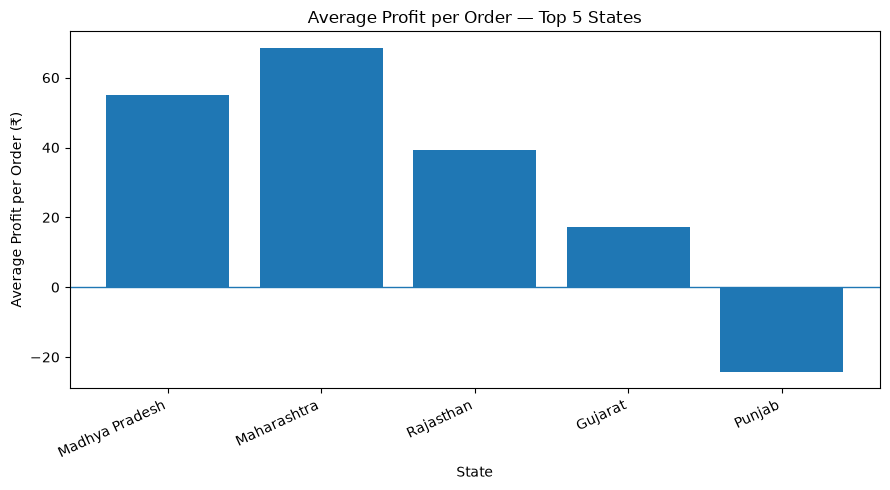

In [6]:
# Visualize average profit per order

plt.figure(figsize=(9, 5))
plt.bar(top_5_states["State"], top_5_states["Average_Profit"])
plt.axhline(0, linewidth=1)
plt.title("Average Profit per Order — Top 5 States")
plt.xlabel("State")
plt.ylabel("Average Profit per Order (₹)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


## 4. Regional Disparities

### Scale

Madhya Pradesh has the highest order count and total sales among the top 5 states, making it the strongest region by scale.

### Profitability

Maharashtra has a higher average profit per order than Madhya Pradesh despite having fewer orders.

Punjab has negative average profit per order, making it the most important profitability concern among the top 5 states.

Gujarat also has relatively low average profitability compared with Madhya Pradesh and Maharashtra.

These results identify **where** the performance disparity exists. The available dataset does not contain enough information to establish the underlying causes, such as pricing, discounting, product mix, or operational costs.


## 5. City-Level Analysis

City-level analysis helps determine whether state-level underperformance is broad-based or concentrated in particular cities.


In [7]:
top_states = top_5_states["State"].tolist()

city_analysis = (
    orders[orders["State"].isin(top_states)]
    .groupby(["State", "City"])
    .agg(
        Order_Count=("Order ID", "nunique"),
        Total_Sales=("Total_Sales", "sum"),
        Average_Profit=("Total_Profit", "mean")
    )
    .reset_index()
    .sort_values(
        ["State", "Order_Count"],
        ascending=[True, False]
    )
)

city_analysis["Total_Sales"] = city_analysis["Total_Sales"].round(2)
city_analysis["Average_Profit"] = city_analysis["Average_Profit"].round(2)

city_analysis


,State,City,Order_Count,Total_Sales,Average_Profit
0,Gujarat,Ahmedabad,17,14230,-51.76
1,Gujarat,Surat,10,6828,134.50
4,Madhya Pradesh,Indore,76,79069,54.72
2,Madhya Pradesh,Bhopal,22,23583,39.59
3,Madhya Pradesh,Delhi,3,2488,173.67
5,Maharashtra,Mumbai,68,61867,24.07
6,Maharashtra,Pune,22,33481,206.32
8,Punjab,Chandigarh,16,12279,-72.06
7,Punjab,Amritsar,9,4507,60.44
9,Rajasthan,Jaipur,19,10076,-39.63


## 6. Cities Requiring Improvement

Cities with negative average profit per order are highlighted as immediate profitability investigation candidates.


In [8]:
improvement_candidates = (
    city_analysis[city_analysis["Average_Profit"] < 0]
    .sort_values("Average_Profit")
    .reset_index(drop=True)
)

improvement_candidates


,State,City,Order_Count,Total_Sales,Average_Profit
0,Punjab,Chandigarh,16,12279,-72.06
1,Gujarat,Ahmedabad,17,14230,-51.76
2,Rajasthan,Jaipur,19,10076,-39.63


### Priority Interpretation

- **Chandigarh:** negative average profit with 16 orders, making it the highest-priority profitability concern.
- **Ahmedabad:** negative average profit with 17 orders and the largest order volume within Gujarat.
- **Jaipur:** negative average profit with 19 orders.
- **Mumbai:** not loss-making in the dataset, but its high order volume is accompanied by comparatively low average profit per order, making it an opportunity for profitability optimization.

Madhya Pradesh and Pune can be considered useful positive-performance benchmarks because they combine meaningful scale with positive profitability.


## 7. Recommendations

1. Prioritize Chandigarh for profitability investigation because it combines negative average profit with relatively high order volume.
2. Investigate Ahmedabad and Jaipur for city-specific profitability issues.
3. Review Mumbai's product mix and profitability because of its high order volume but comparatively low average profit per order.
4. Use Madhya Pradesh and Pune as benchmark regions for understanding positive performance.
5. Investigate pricing, discounting, product mix, and operational factors using additional business data before attributing the observed disparities to a specific cause.


## 8. Data Quality Note

The dataset contains 3 records where **Delhi appears as the city under Madhya Pradesh**. This is treated as a data-quality inconsistency and is not used as a basis for a regional business conclusion.


## Conclusion

The regional analysis shows that **order volume and profitability do not always move together**. Madhya Pradesh leads on scale, while Maharashtra achieves higher average profit per order among the top five states. Punjab shows the clearest profitability concern, while city-level analysis identifies Chandigarh, Ahmedabad, and Jaipur as priority areas for investigation.

The analysis therefore supports a targeted regional strategy rather than applying the same intervention across an entire state.
